# 1 · Seismic imaging: sharpening features with quantum edge detection
### المصدر · Source — رحلة الكم من مصدر الطاقة إلى الاستدامة · Quantum Journey from Energy Source to Sustainability
*Quantum Computing Challenge 2026, Riyadh · Team 1 · Prepared by Ahmed Elghadban, Quantumy*<br><sub>Reviewed by Ola Tarig</sub>

| | |
|---|---|
| Use case | Find the edges and faults in a seismic image of the ground |
| Algorithm | Quantum Hadamard edge detection (amplitude encoding, shift, interference) |
| Toy size | 7 qubits, runs in under 1 min on a laptop |
| Day 1 | read sections 0–2 |
| Day 2 | sections 3–6, build, pitch |

In [1]:
# Setup: run me first. On Colab this clones the repo and installs the pinned packages (about 1 minute).
import sys, os, subprocess
if "google.colab" in sys.modules and not os.path.exists("Quantum-Computing-Challenge"):
    subprocess.run(["git", "clone", "-q", "https://github.com/QTACInstitute/Quantum-Computing-Challenge.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "Quantum-Computing-Challenge/requirements.txt"], check=True)
ROOT = "Quantum-Computing-Challenge" if os.path.exists("Quantum-Computing-Challenge/qff") else ".."
sys.path.insert(0, ROOT)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
import qff
SEED = qff.SEED            # 2026
DATA = os.path.join(ROOT, "data")

## 0 · The journey so far — رحلة الكم
**«من المصدر إلى استخدام الطاقة»** · From the wellspring to the lamp

Before you switch on a lamp tonight, energy will have made one journey. It is found, it is moved, it is stored, and then it is used. Ten teams follow that journey today. Each team owns one moment of it, and each moment has a problem that is hard for ordinary computers at full scale.

1. **المصدر · Source.** Find the energy and decide where to harvest it: read the rock under the ground, place the turbines in the wind.
2. **الطريق · Move.** Get it across the country: watch the grid, route the ships, decide which power stations run.
3. **المخزن · Store.** Keep it for later, and keep carbon out of the air: batteries, hydrogen, capture materials. This is chemistry.
4. **استخدام الطاقة · Use.** Spend it well: make fresh water, charge and discharge a fleet of cars.

Your notebook is one chapter. The cell below lights your stop and lists all ten chapters so you can see who comes before and after you. When you pitch, start by saying where in the journey you are.

One rule for the whole challenge: **be honest about what is real.** As of November 2026 nobody has shown a quantum computer beating the best classical method on any of these ten problems. Your job is to explain the problem, show the idea on a small example, and say clearly what the small example does and does not prove.

In [2]:
from qff.day import show_day
show_day(stop=1, challenge=1)

## 1 · This stop — هذه المحطة

**The problem.** To find oil, gas or geothermal heat, geophysicists send sound waves into the ground and record the echoes. The echoes are processed into a picture of the layers of rock, a **seismic image**. The interesting parts of the picture are the *edges*: where one layer ends and the next begins, and especially **faults**, places where the rock has cracked and one side has slipped. Making those edges sharp and finding them reliably is the step this notebook is about.

**Who faces it.** An energy company's subsurface imaging team, or a geophysical survey contractor that processes seismic data.

<div style="border:1px solid rgba(208,38,112,0.35);border-left:6px solid #D02670;background:rgba(208,38,112,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#D02670;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🌍 Real world · في الواقع</span>

**What is real today.** The WEF/Aramco paper (Case 1, p. 13) reports Aramco researchers sharpening a seismic imaging step on 2-D data with D-Wave hybrid quantum-classical systems. Classical image filters (gradient and Sobel filters, and now machine learning) are mature, fast and run on GPUs. Real surveys are three-dimensional and can be terabytes in size. As far as we know, nobody has shown a quantum method beating them (see the rule in section 0).

</div>

**Why a quantum computer might help.** An image of 2ⁿ pixels fits into the amplitudes of only n qubits, and a few gates then act on *every* pixel at once; interference makes equal neighbours cancel and different neighbours stand out, which is exactly what an edge is. What is still missing: loading the image into amplitudes costs about as many gates as there are pixels, and reading the answer back needs many repeated runs.

| Paper's method | Our teaching route |
|---|---|
| D-Wave hybrid quantum-classical systems on 2-D seismic data (Case 1, p. 13) | Quantum Hadamard edge detection (QHED) on a 7-qubit simulator in Qiskit: a fixed three-step circuit, chosen because it builds on the Hadamard-and-interference ideas of Part 1 of the lectures. Our route comes from separate reporting (The Quantum Insider, 13 Oct 2025) on Aramco work with a GPU quantum emulator, not from the paper |

## 2 · Made small — المسألة مصغَّرة

Our toy "seismic section" is an 8×8 grid of 64 pixels. Three flat layers of rock reflect with strength 0.2, 0.9 and 0.5. A vertical **fault** at column 4 slips the right half down by two rows, so the layers on the right sit lower than on the left. A good edge detector should draw the layer boundaries and show the fault as a jump in the boundaries.

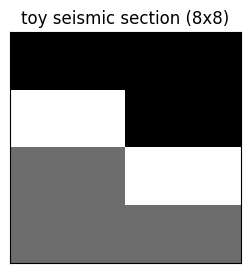

In [3]:
QUBITS = 7                       # the test runner reads this: 6 qubits hold 64 pixels, plus 1 helper (ancilla) qubit


def seismic_section():
    """The 8x8 toy section: three layers (0.2, 0.9, 0.5) and a fault at column 4 that drops the right half by two rows."""
    img = np.zeros((8, 8))
    for c in range(8):
        drop = 0 if c < 4 else 2
        for r in range(8):
            rr = r - drop
            img[r, c] = 0.2 if rr < 2 else (0.9 if rr < 4 else 0.5)
    return img


img = seismic_section()
qff.plots.show_image(img, "toy seismic section (8x8)");

**Classical baseline first.** An edge is a place where a pixel differs from its neighbour. So subtract each pixel from the one next to it, once going across (horizontal scan) and once going down (vertical scan), and call it an edge if the difference is bigger than a threshold of 0.1. The last column (or row) has no neighbour on its far side, so we set its difference to zero. We also show a Sobel filter, the kind of ready-made filter used in industry image-processing, for comparison (picture only).

edge pixels: horizontal scan 4, vertical scan 16, either scan 19
work: 64 subtractions per direction


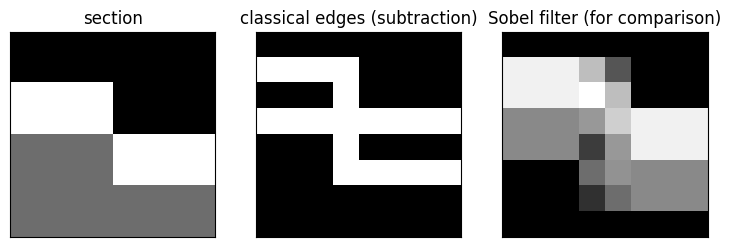

In [4]:
# Classical baseline: always runs first.
import time
from scipy import ndimage

THRESHOLD = 0.1


def classical_edges(image, threshold=THRESHOLD):
    """Neighbour differences. Returns (horizontal diff, vertical diff, edge mask); the wrapped last column / row is zeroed."""
    gh = image - np.roll(image, -1, axis=1)          # pixel minus the pixel to its right
    gv = image - np.roll(image, -1, axis=0)          # pixel minus the pixel below it
    gh[:, -1] = 0
    gv[-1, :] = 0
    return gh, gv, (np.abs(gh) > threshold) | (np.abs(gv) > threshold)


t0 = time.perf_counter()
gh_classical, gv_classical, edges_classical = classical_edges(img)
classical_seconds = time.perf_counter() - t0
n_h, n_v = int((np.abs(gh_classical) > THRESHOLD).sum()), int((np.abs(gv_classical) > THRESHOLD).sum())
print(f"edge pixels: horizontal scan {n_h}, vertical scan {n_v}, either scan {int(edges_classical.sum())}")
print("work: 64 subtractions per direction")

sobel = np.hypot(ndimage.sobel(img, axis=1), ndimage.sobel(img, axis=0))
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
qff.plots.show_image(img, "section", ax=axes[0])
qff.plots.show_image(edges_classical, "classical edges (subtraction)", ax=axes[1])
qff.plots.show_image(sobel, "Sobel filter (for comparison)", ax=axes[2]);

Subtraction finds 19 edge pixels in a blink. That is the honest starting point: **on this toy the classical method is instant, and a quantum circuit cannot beat instant.** The toy exists so you can see how the quantum method works, and so you can see where its cost hides.

## 3 · The algorithm — الخوارزمية

### 3.0 · The map of this section

<div style="border:1px solid rgba(0,125,121,0.35);border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">💡 Idea · فكرة</span>

**Edge detection in one sentence.** Put the whole image into the *amplitudes* of a few qubits, make every pixel interfere with its neighbour using only a Hadamard gate, a shift and another Hadamard gate, and read the *differences* off the result: equal neighbours cancel, a jump survives, and a jump is an edge.

</div>

There is **no tuning loop** in this notebook (unlike QAOA or VQE): the circuit is fixed, so everything is about *what the state contains* after each gate. We build the idea from two things you already know: lists of numbers (vectors) and probability. Every step has a **numbered equation** and, right after it, the **code cell that implements it**.

| Step | What happens | Equation | Where in the code | Your task |
|---|---|---|---|---|
| 3.1 | An image becomes the amplitudes of a quantum state | (1) | `row`, `row_norm` | |
| 3.2 | A helper qubit in superposition (Hadamard gate) | (2) | `by_hand` stage 1 | |
| 3.3 | The shift moves every pixel by one place | (3) | `shift_matrix` | |
| 3.4 | A second Hadamard turns neighbours into sum and difference | (4), (5) | `by_hand` stages 2 and 3 | |
| 3.5 | A worked example you can do on paper (2 pixels) | (1) to (5) | `by_hand` | **T1** (4 pixels, in Qiskit) |
| 3.6 | The full 8×8 image, then horizontal and vertical scans | (6) | `qhed` | **T2** |
| 3.7 | What a real device gives: shots instead of amplitudes | (7), (8) | `sampled_edges` | **T3** |

Words in **bold** are new ideas; each is explained where it first appears, and the Arabic term sits in a small table next to it.

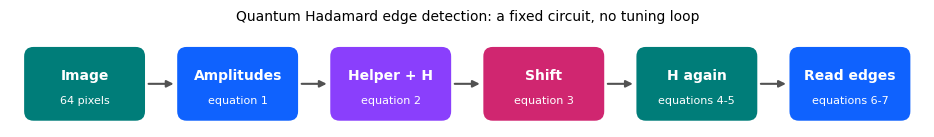

In [5]:
qff.plots.plot_flow(
    [("Image", "64 pixels", "source"), ("Amplitudes", "equation 1", "move"), ("Helper + H", "equation 2", "store"),
     ("Shift", "equation 3", "use"), ("H again", "equations 4-5", "source"), ("Read edges", "equations 6-7", "move")],
    title="Quantum Hadamard edge detection: a fixed circuit, no tuning loop");

**Symbol table** (the right column is where the symbol lives in the code).

| Symbol | Meaning | In the code |
|---|---|---|
| $v_i$, $\lVert v\rVert$ | pixel $i$ (row by row), length of the pixel list | `image.flatten()`, `np.linalg.norm(v)` |
| $N=2^n$, $n$ | number of pixels, number of pixel qubits (6) | `v.size`, `int(np.log2(v.size))` |
| $\alpha_i$ | amplitude of pixel $i$ after normalising | `v / norm` |
| $\lvert i\rangle$ | basis state number $i$ | position $i$ of the state vector |
| $a$, $k=2i+a$ | helper qubit value; position in the 128-long list | `state[0::2]` (helper 0), `state[1::2]` (helper 1) |
| $H$ | Hadamard gate: sum and difference over $\sqrt2$ | `qc.h(0)` |
| $S$ | cyclic shift: position $k\to k-1$ | `shift_matrix(n + 1)` |
| $2\lVert v\rVert\cdot\text{odd}$ | difference $v_i-v_{i+1}$ | `2 * norm * odd` |
| $f$ | frequency of an outcome over many shots | `counts[key] / shots` |

<div style="border:1px solid rgba(15,98,254,0.35);border-left:6px solid #0F62FE;background:rgba(15,98,254,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#0F62FE;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">∑ Math · رياضيات</span>&nbsp; **The line to remember**

**The one line to remember.** Hadamard, shift, Hadamard turns neighbours into sum and difference: $2\lVert v\rVert\times(\text{amplitude at an odd position})=v_i-v_{i+1}$ (equation 4). Equal neighbours cancel; a jump survives; a jump is an edge.

</div>

### 3.1 · From an image to a quantum state

**Start with what you know.** Our section is 64 numbers (pixel brightnesses), say $v=(v_0,v_1,\dots,v_{63})$, read row by row. The **length** (norm) of this list is $\lVert v\rVert=\sqrt{v_0^2+v_1^2+\dots+v_{63}^2}$. Six qubits hold a list of $2^6=64$ numbers called **amplitudes** $\alpha_i$, and a quantum state needs the squares of its amplitudes to add up to 1, because $|\alpha_i|^2$ is the **probability** of measuring $i$. So we divide the list by its length:

$$|\psi\rangle=\sum_{i=0}^{N-1}\alpha_i\,|i\rangle,\qquad \alpha_i=\frac{v_i}{\lVert v\rVert},\qquad \sum_i\alpha_i^2=1,\qquad n=\log_2 N\ \text{qubits} \tag{1}$$

This is **amplitude encoding**: pixel number $i$ becomes amplitude number $i$. $|i\rangle$ ("ket $i$") is just a *name tag* for the basis state number $i$: a column of $N$ numbers with a single 1 at position $i$. Doubling the number of pixels needs only **one more qubit**; that is the attraction of the method. (It is also its catch: *loading* the amplitudes costs about one gate per pixel, as section 4 shows.)

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**Amplitudes can be negative.** Probabilities cannot, but amplitudes can: only their *squares* are probabilities. The sign (more generally, the **phase**) is invisible to a measurement of that state, but it decides how amplitudes *add or cancel* when they meet. That meeting is called **interference**, and it is the whole trick of this notebook.

</div>

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Amplitude encoding | الترميز بالسعة | I | Norm (length of a vector) | المعيار (طول المتجه) | I |
| Amplitude | السعة | G | Normalisation | التطبيع | I |
| Probability | الاحتمال | I | Interference | التداخل | G |
| Qubit | كيوبت | G | Phase | الطور | U |
| Quantum state | الحالة الكمومية | I | Pixel | بكسل | I |

In [6]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


def shift_matrix(n):
    """The n-qubit unitary that moves basis state k to k - 1 (cyclically). Used as a single gate here."""
    return np.roll(np.eye(2 ** n), 1, axis=1)


# Warm-up instance: one row of four pixels, [0, 0, 1, 1]: dark, dark, bright, bright. Two data qubits + 1 ancilla = 3 qubits.
row = np.array([0.0, 0.0, 1.0, 1.0])
row_norm = np.linalg.norm(row)
print("row:", row, "| length:", round(row_norm, 4), "| amplitudes after dividing by it:", np.round(row / row_norm, 3))

row: [0. 0. 1. 1.] | length: 1.4142 | amplitudes after dividing by it: [0.    0.    0.707 0.707]


### 3.2 · A helper qubit and the Hadamard gate

We add **one more qubit**, the helper (the **ancilla**), as qubit 0, in state $|0\rangle$. The pixel qubits are qubits $1,\dots,6$. With the helper as the lowest bit, the basis state "pixel $i$, helper $a$" ($a=0$ or $1$) sits at position $k=2i+a$ of the list of 128 amplitudes: **even positions have helper 0, odd positions have helper 1.** At the start only the even positions are filled:

$$\text{amplitude at }2i=\alpha_i,\qquad\text{amplitude at }2i+1=0$$

The **Hadamard gate** $H=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ acts on one qubit. It turns $|0\rangle$ into the equal mixture $\frac1{\sqrt2}(|0\rangle+|1\rangle)$, called a **superposition**, and it turns $|1\rangle$ into $\frac1{\sqrt2}(|0\rangle-|1\rangle)$. In plain words, on every pair of amplitudes $(x,y)$ that differ only in the helper bit, it computes **sum and difference**, each divided by $\sqrt2$:

$$H:\ (x,\,y)\ \longmapsto\ \Bigl(\tfrac{x+y}{\sqrt2},\ \tfrac{x-y}{\sqrt2}\Bigr) \tag{H}$$

Applied once to the helper at the start ($x=\alpha_i$, $y=0$) it gives

$$\text{amplitude at }2i=\frac{\alpha_i}{\sqrt2},\qquad\text{amplitude at }2i+1=\frac{\alpha_i}{\sqrt2} \tag{2}$$

so every pixel now exists twice, once with helper 0 and once with helper 1.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Ancilla (helper qubit) | كيوبت مساعد | G | Basis state | حالة القاعدة | I |
| Hadamard gate | بوابة هادامارد | G | Quantum gate | البوابة الكمومية | U |
| Superposition | التراكب | G |  |  |  |

### 3.3 · The shift

Next a **shift** $S$ moves every amplitude one place down the list of 128: the amplitude at position $k$ goes to position $k-1$, and position 0 wraps round to the end (a *cyclic* shift). It is a **unitary**: a reversible operation that only rearranges the amplitudes, so the squares still add up to 1. It acts on **all 128 amplitudes at once**, which is where the "parallel" in "quantum" comes from here. After the shift the amplitude at position $m$ is the one that used to be at $m+1$. Using (2):

$$\text{amplitude at }2i=\frac{\alpha_i}{\sqrt2},\qquad\text{amplitude at }2i+1=\frac{\alpha_{i+1}}{\sqrt2} \tag{3}$$

Look at the second equation: the odd position $2i+1$ used to hold pixel $i$ (helper 1) at the *next* position $2i+2$, which is pixel $i+1$ with helper 0. So **the odd positions now hold the right-hand neighbour** $\alpha_{i+1}$, while the even positions still hold pixel $i$ itself. The shift has put each pixel and its neighbour into the same pair (same $i$, helpers 0 and 1), which is exactly the pair a Hadamard on the helper combines.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Cyclic shift | الإزاحة الدورية | I | Reversible | عكوس | I |
| Unitary matrix | مصفوفة عكوسة/وحدوية | G |  |  |  |

### 3.4 · Interference: sum and difference

Apply $H$ to the helper once more. By rule (H) it combines the pair at positions $2i$ and $2i+1$ from (3):

$$\begin{aligned}\text{amplitude at }2i&=\frac{\alpha_i+\alpha_{i+1}}{2}\quad&&(\text{helper }0:\ \text{sum})\\ \text{amplitude at }2i+1&=\frac{\alpha_i-\alpha_{i+1}}{2}=\frac{v_i-v_{i+1}}{2\lVert v\rVert}\quad&&(\text{helper }1:\ \text{difference})\end{aligned} \tag{4}$$

**The odd positions (helper reads 1) hold the difference between a pixel and its right-hand neighbour**, divided by $2\lVert v\rVert$. If the two pixels are equal the two contributions *cancel* (destructive interference) and the amplitude is 0. If they differ, an amplitude survives. A pixel that differs from its neighbour is an edge, so the odd positions are an edge map: **$2\lVert v\rVert\times$(odd amplitude) $=v_i-v_{i+1}$.** The even positions hold sums and are not needed.

How much of the probability lands on edge information? The odd positions carry every pixel pair's squared difference, so

$$P(\text{helper}=1)=\sum_i\frac{(v_i-v_{i+1})^2}{4\lVert v\rVert^2} \tag{5}$$

This number is small for a mostly flat image (about 3.5% for ours), and that matters for shots (section 3.7).

<div style="border:1px solid rgba(0,125,121,0.35);border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">💡 Idea · فكرة</span>

**Why it is an edge detector.** Subtracting neighbours is what every classical edge filter does. The quantum circuit does *all* the subtractions with three gates (H, shift, H), on all pixels at once, because the shift and the Hadamard act on the whole list of amplitudes together. What it does not do for free is getting the picture in (loading) and the answer out (measuring).

</div>

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**Wrap-around.** The shift is cyclic, so the last pixel is compared with the *first*. In an image flattened row by row, the last pixel of each row is compared with the first pixel of the *next* row. These are false edges, and we mask them out.

</div>

### 3.5 · A worked example you can check on paper

Take the smallest image there is: **two pixels, $v=(0,1)$** (dark, bright). Then $\lVert v\rVert=1$, $\alpha=(0,1)$ and there are $2$ pixel positions $\times$ helper = 4 amplitudes, written in the order $k=0,1,2,3$ = (pixel 0 helper 0, pixel 0 helper 1, pixel 1 helper 0, pixel 1 helper 1).

| After | $k=0$ | $k=1$ | $k=2$ | $k=3$ | Rule used |
|---|---|---|---|---|---|
| load the pixels | 0 | 0 | 1 | 0 | (1): amplitude at $2i$ is $\alpha_i$ |
| $H$ on the helper | 0 | 0 | $\frac1{\sqrt2}$ | $\frac1{\sqrt2}$ | (2) |
| shift ($k\to k-1$) | 0 | $\frac1{\sqrt2}$ | $\frac1{\sqrt2}$ | 0 | (3): position 0 wraps to the end |
| $H$ on the helper | $\frac12$ | $-\frac12$ | $\frac12$ | $\frac12$ | (4): pairs $(0,\frac1{\sqrt2})$ and $(\frac1{\sqrt2},0)$ |

Do the last row yourself with rule (H): pair $(k=0,1)=(0,\frac1{\sqrt2})$ gives $\bigl(\frac{0+1/\sqrt2}{\sqrt2},\frac{0-1/\sqrt2}{\sqrt2}\bigr)=(\frac12,-\frac12)$; pair $(k=2,3)=(\frac1{\sqrt2},0)$ gives $(\frac12,\frac12)$.

**Read the odd positions** ($k=1$ and $k=3$, helper 1): $-\frac12$ and $+\frac12$. Multiply by $2\lVert v\rVert=2$: $-1$ and $+1$. And indeed $v_0-v_1=0-1=-1$ and $v_1-v_0=1-0=+1$ (the second is the wrap-around: pixel 1 is compared with pixel 0). Both are non-zero, so *both* places are edges. With two pixels that is all there is. Probability of helper 1 by (5): $\frac{1+1}{4}=\frac12$ ✓ (two amplitudes of $\frac12$ squared: $\frac14+\frac14$).

The next cell runs exactly these steps with numpy, with no quantum library, so you can see each stage. After T1 you will check that Qiskit gives the same final row.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Constructive / destructive interference | تداخل بنّاء / تداخل هدّام | I | Normalisation | التطبيع | I |
| Helper qubit (ancilla) | كيوبت مساعد | G | Pixel | البكسل (عنصر الصورة) | I |

    load: [0. 0. 1. 0.]
       H: [0.     0.     0.7071 0.7071]
   shift: [0.     0.7071 0.7071 0.    ]
 H again: [ 0.5 -0.5  0.5  0.5]
odd positions: [-0.5  0.5] -> times 2*norm: [-1.  1.] | P(helper = 1) = 0.5
flat row [1, 1, 1, 1], odd positions: [-0. -0. -0. -0.] -> every difference cancels
OK: equal neighbours cancel; only a difference between neighbours survives.


array([<Axes: title={'center': 'load'}, xlabel='position k', ylabel='amplitude'>,
       <Axes: title={'center': 'H'}, xlabel='position k'>,
       <Axes: title={'center': 'shift'}, xlabel='position k'>,
       <Axes: title={'center': 'H again'}, xlabel='position k'>],
      dtype=object)

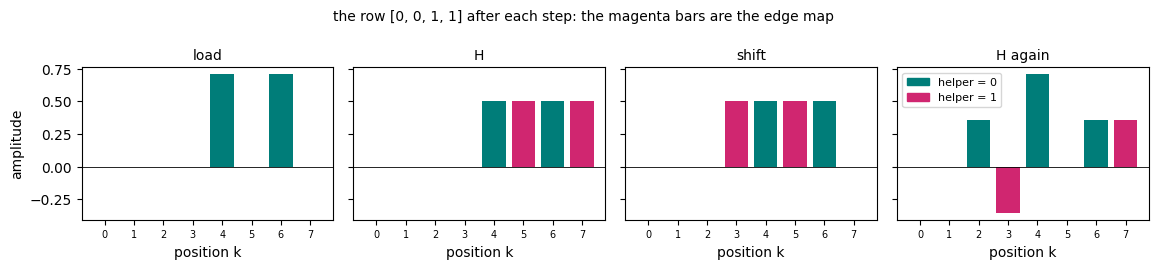

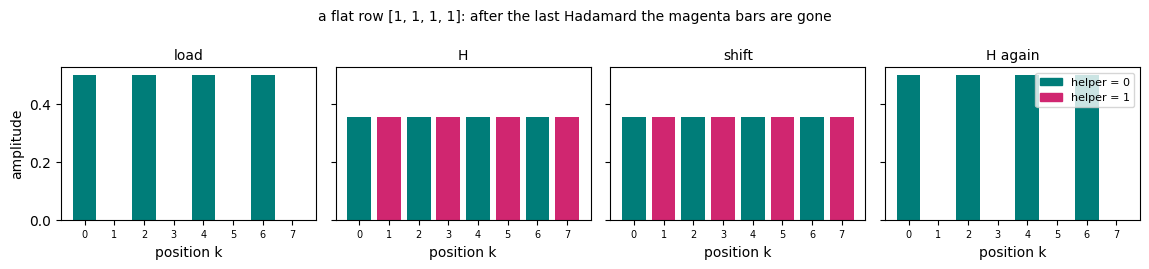

In [7]:
# Equations (1)-(5) with plain numpy, stage by stage. Position k = 2*i + a: even k = helper 0, odd k = helper 1.
H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)                      # the Hadamard gate as a matrix


def hadamard_on_helper(state):
    """Rule (H): on every pair (position 2i, position 2i+1) compute (x + y, x - y) / sqrt(2)."""
    return (state.reshape(-1, 2) @ H1.T).reshape(-1)


def by_hand(v):
    """The four stages of the edge-detection circuit for a list of 2^n pixel values: returns a dict name -> state vector."""
    v = np.asarray(v, dtype=float)
    norm = np.linalg.norm(v)
    s0 = np.zeros(2 * v.size)
    s0[0::2] = v / norm                                             # equation (1): pixel i at position 2i, helper = 0
    s1 = hadamard_on_helper(s0)                                     # equation (2)
    s2 = np.roll(s1, -1)                                            # equation (3): the amplitude at k moves to k-1
    s3 = hadamard_on_helper(s2)                                     # equation (4)
    return {"load": s0, "H": s1, "shift": s2, "H again": s3}, norm


stages2, norm2 = by_hand([0, 1])
for name, st in stages2.items():
    print(f"{name:>8}:", np.round(st, 4))
odd2 = stages2["H again"][1::2]
print("odd positions:", np.round(odd2, 4), "-> times 2*norm:", 2 * norm2 * odd2, "| P(helper = 1) =", round(float((odd2 ** 2).sum()), 4))
assert np.allclose(stages2["H again"], [0.5, -0.5, 0.5, 0.5]) and np.allclose(2 * norm2 * odd2, [-1, 1])

# The same stages for the four-pixel row of T1, drawn as bar charts (helper 0 = teal bars, helper 1 = magenta bars).
stages4, norm4 = by_hand(row)
qff.plots.plot_amplitude_stages(stages4, suptitle="the row [0, 0, 1, 1] after each step: the magenta bars are the edge map")

# Destructive interference, checked: a flat row (all pixels equal) must give an edge map of exactly zero.
flat_odd = by_hand([1, 1, 1, 1])[0]["H again"][1::2]
print("flat row [1, 1, 1, 1], odd positions:", np.round(flat_odd, 4), "-> every difference cancels")
assert np.allclose(flat_odd, 0), "equal neighbours must cancel exactly (destructive interference)"
print("OK: equal neighbours cancel; only a difference between neighbours survives.")
qff.plots.plot_amplitude_stages(by_hand([1, 1, 1, 1])[0], suptitle="a flat row [1, 1, 1, 1]: after the last Hadamard the magenta bars are gone")

<div style="border:2px dashed #007D79;border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🧪 Try it · جرّب</span>

Change `row` in the cell above to `[0, 1, 0, 1]` or `[1, 1, 1, 1]` (and rerun both cells). For the all-equal row every magenta bar in the last panel should be exactly 0: that is the cancellation. For the alternating row every bar is large. **Predict before you run.**

</div>

### 🧰 Toolbox: how the calls you will need are written · صندوق الأدوات

No internet? No problem. The cell under this table runs each call once on a **small toy that has nothing to do with the task**, so you can see the exact spelling, the order of the arguments, and what comes back. Run it, read the printed lines, and come back to it whenever a hint says "a method of ...". *What* to build, and with *which numbers*, is your job.

| To do | How it is written | What you get |
|---|---|---|
| a circuit with 3 qubits | `qc = QuantumCircuit(3)` | all qubits start in $\lvert0\rangle$ |
| Hadamard on qubit 0 | `qc.h(0)` | one gate; `qc.h(range(3))` puts it on every qubit in the list |
| load amplitudes into *some* qubits | `qc.initialize(amplitudes, [1, 2])` | `amplitudes` is a normalised list of $2^k$ numbers for $k$ listed qubits |
| apply a matrix as one gate | `qc.unitary(matrix, [0, 1, 2])` | `matrix` is $2^k\times2^k$ for $k$ listed qubits |
| read all amplitudes | `Statevector(qc).data` | a complex numpy array of length $2^n$ (position $k$: qubit $i$ is bit $i$ of $k$) |
| count the gates | `qc.count_ops()` | a dictionary such as `{'h': 1, 'unitary': 1}` |
| seeded random numbers | `rng = np.random.default_rng(SEED)`, then `rng.normal(0, sigma, size)` | the same numbers on every run |
| keep numbers inside $[0,1]$ | `np.clip(a, 0, 1)` | smaller values become 0, larger become 1 |
| the helper `classical_edges(image, t)` | `gh, gv, mask = classical_edges(image, t)` | **three** things: horizontal differences, vertical differences, and the yes/no edge mask (the last one) |

In [8]:
# Toolbox for 01, on a 2-qubit toy that has nothing to do with the image.
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

toy = QuantumCircuit(2)                                   # 2 qubits, both start in |0>
toy.initialize([0.6, 0.8], [1])                           # load a normalised amplitude list into qubit 1 only
toy.h(0)                                                  # Hadamard on qubit 0
toy.unitary(np.array([[0, 1], [1, 0]]), [0])              # a 2 x 2 matrix applied as one gate to qubit 0 (this matrix is the X gate)
amp = Statevector(toy).data                               # the 4 amplitudes (position k = 2 * qubit1 + qubit0)
print("amplitudes:", np.round(amp.real, 3), "| gates:", dict(toy.count_ops()))
assert np.allclose(amp.real, np.array([0.6, 0.6, 0.8, 0.8]) / np.sqrt(2)), "the toolbox toy should give these amplitudes"
rng = np.random.default_rng(SEED)                         # the day's seeded generator
print("four noisy numbers kept inside [0, 1]:", np.round(np.clip(rng.normal(0.5, 0.3, 4), 0, 1), 3))
print("OK: toolbox 01 ran.")

amplitudes: [0.424 0.424 0.566 0.566] | gates: {'initialize': 1, 'h': 1, 'unitary': 1}
four noisy numbers kept inside [0, 1]: [0.262 0.572 0.    0.919]
OK: toolbox 01 ran.


### T1 · Warm-up: the circuit for four pixels · التمرين ١

**What you are about to build, and why.** So far we computed the stages with numpy. Now you build the *same* thing as a Qiskit circuit for the four-pixel row $[0,0,1,1]$ (dark, dark, bright, bright): 3 qubits, 2 for the four pixels and 1 helper. You will see the same odd-position amplitudes, and the same wrap-around from pixel 3 back to pixel 0.

**The formulas you implement:** equations (1) to (4), one gate for each: load $\alpha=v/\lVert v\rVert$ on the pixel qubits (qubits 1 and 2), $H$ on qubit 0, the shift $S$ on all three qubits, $H$ on qubit 0 again. Then read the odd positions (`[1::2]`) and multiply by $2\lVert v\rVert$ to get the differences $v_i-v_{i+1}$.

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

There are four steps, in this order: load the row into a 3-qubit circuit, Hadamard, shift, Hadamard. Which qubit is the helper, and which qubits hold the pixels (see 3.2)? Qiskit has a ready-made circuit method for loading a list of amplitudes into chosen qubits, and another for applying a matrix as one gate to chosen qubits. Look for them by what they do. Check the sizes before you code: 3 qubits means a list of how many amplitudes, and at which positions of that list does the helper read 1?

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Use `initialize` on the *pixel* qubits only (with the normalised row), `h` on the helper, then the matrix gate (`unitary`) built from `shift_matrix` acting on *all* qubits, then `h` on the helper again. To read the result: take the state vector of the circuit (`Statevector`), keep every second amplitude starting from position 1, keep the real parts, and undo the division by the length of the row. Remember that Qiskit counts qubits from the right, so qubit 0 changes fastest along the state vector: that is why the helper's value is the parity (even or odd) of the position.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
warm = ______              # a circuit with 3 qubits
# 1. load the normalised row into the two pixel qubits (which qubit numbers?)
# 2. Hadamard on the helper
# 3. the shift, as one matrix gate on all three qubits
# 4. Hadamard on the helper again
odd = ______               # the real parts of the amplitudes at the positions where the helper reads 1
warm_diff = ______         # undo the normalisation (equation 4 tells you the factor)
```
Test yourself: `odd` has 4 numbers and only two of them are non-zero.

</details>

In [9]:
# TODO (team) T1: warm-up: build the 3-qubit edge-detection circuit for the row [0, 0, 1, 1]
# Goal: `warm` is a 3-qubit QuantumCircuit that runs the edge-detection steps of 3.2-3.4 on the row [0, 0, 1, 1].
# Keep `odd` (the amplitudes where the helper is 1, real parts) and `warm_diff` (the differences recovered from them).
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

# Helper function and input defined in section 3.1
def shift_matrix(n):
    return np.roll(np.eye(2 ** n), 1, axis=1)

row = np.array([0.0, 0.0, 1.0, 1.0])

# 3 qubits: 2 for pixels (4 pixels) + 1 ancilla (qubit 0)
warm = QuantumCircuit(3)

# Normalize the 4-pixel row and encode into pixel qubits
norm = np.linalg.norm(row)
warm.initialize(row / norm, [1, 2])

# Put ancilla in superposition to prepare for interference
warm.h(0)

# Cyclic shift to align each pixel with its neighbor
warm.unitary(shift_matrix(3), [0, 1, 2])

# Interfere neighbor amplitudes: equal cancels out, difference survives
warm.h(0)

# Extract odd-indexed amplitudes (where ancilla is |1>) to get edges
state = np.real(Statevector(warm).data)
odd = state[1::2]
warm_diff = 2 * norm * odd

In [10]:
# Self-check
assert warm.num_qubits == 3, "T1: the warm-up circuit has 3 qubits (2 pixel qubits + 1 ancilla)"
assert np.allclose(odd, [0, -0.35355, 0, 0.35355], atol=1e-4), "T1: the odd amplitudes should be about [0, -0.354, 0, 0.354]"
assert np.allclose(warm_diff, [0, -1, 0, 1], atol=1e-9), "T1: differences should be [0, -1, 0, 1]: pixel 1 vs 2 is the edge, and 3 vs 0 is the wrap-around"

OK: Qiskit agrees with the paper-and-pencil calculation.


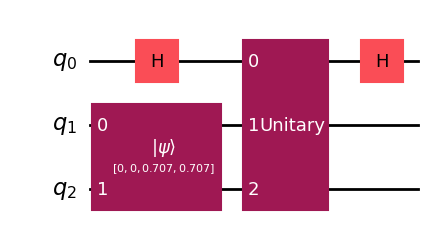

In [11]:
# Check: your Qiskit circuit ends in the same state as the numpy stages of 3.5.
assert np.allclose(np.real(Statevector(warm).data), stages4["H again"]), "T1: the circuit should end in the same state as the numpy stages"
print("OK: Qiskit agrees with the paper-and-pencil calculation.")
try:
    display(warm.draw("mpl"))
except Exception:                                      # drawing with matplotlib needs pylatexenc; fall back to text
    print(warm.draw("text"))




Read the result: position 1 is non-zero (pixel 1 is dark, pixel 2 is bright: an edge) and position 3 is non-zero too. Pixel 3 is bright and the list **wraps round** to pixel 0, which is dark. The shift is cyclic, so the last pixel is compared with the first. In a 2-D image flattened row by row, that means the last pixel of each row is compared with the first pixel of the *next* row. Those comparisons are false edges, and we must mask them out.

### 3.6 · The full image, and the two scans

**The full image.** 64 pixels need 6 qubits, plus the helper: 7 qubits, a state vector of 128 amplitudes. The shift is built here as a dense 128×128 matrix and applied as one gate. That is fine for a simulator, but it is *not* how hardware would do it: a shift by one is a ladder of multi-controlled X gates, and we come back to that cost in section 4.

### T2 · Core step: the edge detector for the whole image · التمرين ٢

**What you are about to build, and why.** In T1 you did four pixels by hand-sized code. T2 turns that into a **function** that works for any image with $2^n$ pixels: `qhed(image)` (*quantum Hadamard edge detection*). The size of the image decides the number of qubits, so the function must compute $n=\log_2 N$ itself instead of using the number 2. It returns the differences as an array shaped like the image, and the circuit.

**The formula you implement:** equations (1) to (4) for general $N$: load $v/\lVert v\rVert$ on qubits $1..n$; $H$ on qubit 0; shift on all $n+1$ qubits; $H$ on qubit 0; then difference $=2\lVert v\rVert\times$ (odd amplitudes), reshaped to the image's shape.

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

Compare with T1. What was hard-coded there that now depends on the image? (The number of pixel qubits, the list of qubit numbers, the length used for normalising.) Work out each of those from the image itself. Which two or three lines of your T1 answer must change when the image has more than four pixels, and which can stay exactly as they were?

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Steps: flatten the image row by row; compute its length (norm); the number of pixel qubits is the base-2 logarithm of the number of pixels; the circuit has one more qubit than that (the helper). Then do exactly the four steps of T1, with the qubit lists computed instead of typed. Finally read the helper-is-1 amplitudes, undo the normalisation, and give them the shape of the image. Return the array and the circuit.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
def qhed(image):
    v = ______             # the pixels as one list, row by row
    norm = ______          # the length of that list
    n = ______             # the number of pixel qubits
    qc = ______            # a circuit with n + 1 qubits
    # load the normalised pixels into qubits 1..n, Hadamard on qubit 0, the shift on ALL qubits, Hadamard on qubit 0
    odd = ______           # real parts of the amplitudes where the helper reads 1
    return ______, qc      # the differences, shaped like the image (what factor undoes the normalisation?)
```

</details>

In [12]:
# TODO (team) T2: write qhed(image) for the full 8x8 section
# Goal: qhed(image) returns (an array shaped like `image` holding image[i] - image[i+1] in flattened order, the circuit).
# It must work for any image with 2**n pixels. Then run it on the seismic section: diff_h, qc = qhed(img).
# TODO (team) T2: write qhed(image) for the full 8x8 section
def qhed(image):
    v = image.flatten().astype(float)
    norm = np.linalg.norm(v)
    n = int(np.log2(v.size))

    # n qubits for image pixels (1 to n) + 1 ancilla (qubit 0)
    qc = QuantumCircuit(n + 1)

    # Encode normalized pixel values into qubits [1..n]
    qc.initialize(v / norm, list(range(1, n + 1)))

    # Hadamard on ancilla
    qc.h(0)

    # Shift unitary across all n+1 qubits
    qc.unitary(shift_matrix(n + 1), list(range(n + 1)))

    # Hadamard interference on ancilla
    qc.h(0)

    # Recover neighbour differences from odd amplitudes
    state = np.real(Statevector(qc).data)
    odd = state[1::2]
    diff = (2 * norm * odd).reshape(image.shape)

    return diff, qc

diff_h, qc = qhed(img)

In [13]:
# Self-check
assert qc.num_qubits == 7, "T2: 6 pixel qubits + 1 ancilla = 7 qubits"
flat_diff = (img.flatten() - np.roll(img.flatten(), -1)).reshape(8, 8)
assert np.abs(diff_h - flat_diff).max() < 1e-10, "T2: the quantum result should equal pixel minus next pixel in flattened order"

**Check against the numpy stages and the probability formula.** The next cell runs the paper-and-pencil stages of 3.5 on the full 64 pixels, and checks that Qiskit's final state (from your `qhed`) is the same, and that equation (5) gives the probability of the helper reading 1.

P(helper = 1): equation (5) 0.03489 | circuit 0.03489
OK: equations (1)-(5) reproduce the circuit.


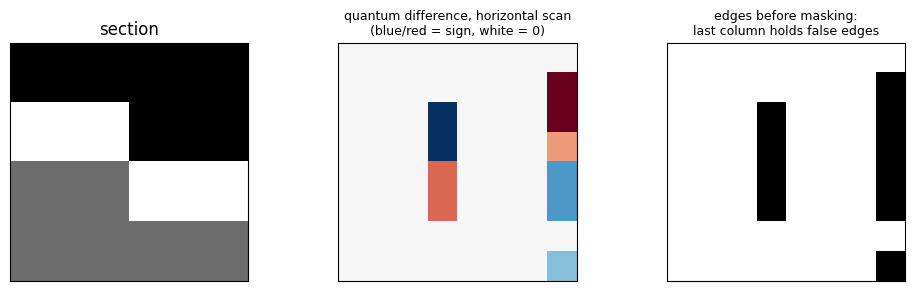

In [14]:
# Check: equation (5) and the numpy stages agree with the Qiskit circuit for the full 8x8 image.
stages64, norm64 = by_hand(img.flatten())
assert np.allclose(np.real(Statevector(qc).data), stages64["H again"]), "the Qiskit circuit and the numpy stages should end in the same state"
v_flat = img.flatten()
p_formula = float(((v_flat - np.roll(v_flat, -1)) ** 2).sum() / (4 * norm64 ** 2))              # equation (5)
p_circuit = float(Statevector(qc).probabilities()[1::2].sum())
print(f"P(helper = 1): equation (5) {p_formula:.5f} | circuit {p_circuit:.5f}")
assert abs(p_formula - p_circuit) < 1e-12
print("OK: equations (1)-(5) reproduce the circuit.")
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
qff.plots.show_image(img, "section", ax=axes[0])
axes[1].imshow(diff_h, cmap="RdBu"); axes[1].set_title("quantum difference, horizontal scan\n(blue/red = sign, white = 0)", fontsize=9)
axes[2].imshow((np.abs(diff_h) > THRESHOLD).astype(int), cmap="gray_r"); axes[2].set_title("edges before masking:\nlast column holds false edges", fontsize=9)
for ax in axes[1:]:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

**Two scans, because an image has two directions.** Equation (4) compares each pixel with the next one *in the flattened list*. For an image $I$ with rows $r$ and columns $c$, flattened row by row, the next pixel is the right-hand neighbour (except at the end of a row, where it wraps to the next row, the false edge of 3.4). To also compare with the pixel *below*, run the same circuit on the **transposed** image (rows and columns swapped) and transpose the answer back:

$$D^{\text{h}}_{r,c}=I_{r,c}-I_{r,c+1}\ \ (\text{from }I),\qquad D^{\text{v}}_{r,c}=I_{r,c}-I_{r+1,c}\ \ (\text{from }I^{\mathsf T}),\qquad \text{edge}\iff |D^{\text{h}}_{r,c}|>t\ \text{ or }\ |D^{\text{v}}_{r,c}|>t \tag{6}$$

with the last column of $D^{\text{h}}$ and the last row of $D^{\text{v}}$ set to zero (the wrap-around). $t$ is the **threshold**: a difference smaller than $t$ is treated as "no edge" (we use 0.1). Two scans cost two circuit runs.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Edge detection | كشف الحواف | I | Fault (geology) | صدع | I |
| Threshold | العتبة | I | Seismic imaging | التصوير الزلزالي | I |
| Transpose | المنقول (المبدّلة) | I | Horizontal / vertical | أفقي / رأسي | I |

**Horizontal scan.** The quantum result `diff_h` equals each pixel minus the *next pixel in flattened order*. Along a row that is the right-hand neighbour, except in the last column, where it is the first pixel of the next row. Zero that column.

**Vertical scan.** Run the same circuit on the *transposed* image (rows and columns swapped), so that "next in flattened order" now means the pixel below. Transpose the answer back, and zero the last row. The two scans use two circuit runs.

horizontal scan, unmasked: edge pixels flagged = 10 | of them in the last column (false, row wrap-around): 6
edge pixels, either scan, after masking: 19 | classical: 19
largest difference between quantum and classical subtraction results: 1.1102230246251565e-16


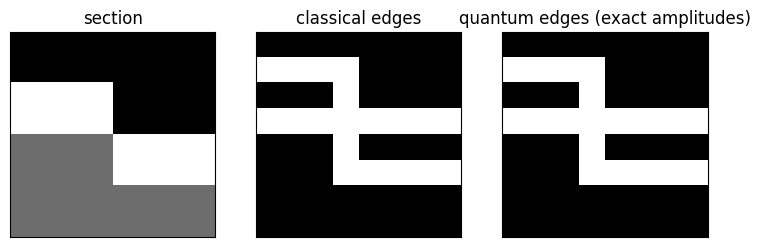

In [15]:
diff_t, _ = qhed(img.T)
gv_quantum = diff_t.T
gh_quantum = diff_h.copy()
print("horizontal scan, unmasked: edge pixels flagged =", int((np.abs(gh_quantum) > THRESHOLD).sum()),
      "| of them in the last column (false, row wrap-around):", int((np.abs(gh_quantum)[:, -1] > THRESHOLD).sum()))
gh_quantum[:, -1] = 0                                  # mask the wrap-around column
gv_quantum[-1, :] = 0                                  # mask the wrap-around row
edges_quantum = (np.abs(gh_quantum) > THRESHOLD) | (np.abs(gv_quantum) > THRESHOLD)
print("edge pixels, either scan, after masking:", int(edges_quantum.sum()), "| classical:", int(edges_classical.sum()))
print("largest difference between quantum and classical subtraction results:",
      max(np.abs(gh_quantum - gh_classical).max(), np.abs(gv_quantum - gv_classical).max()))

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
qff.plots.show_image(img, "section", ax=axes[0])
qff.plots.show_image(edges_classical, "classical edges", ax=axes[1])
qff.plots.show_image(edges_quantum, "quantum edges (exact amplitudes)", ax=axes[2]);

### 3.7 · What a real device gives: shots, not amplitudes

**But a real device does not give you the amplitudes.** On a simulator we peeked at the state vector; hardware only lets you **measure**, and each measurement returns *one* outcome. We run the circuit many times (each run is a **shot**) and count how often each outcome appears. The frequency $f$ of an outcome estimates its probability (amplitude squared). By (4) the probability of the odd position $2i+1$ is $\bigl(\frac{v_i-v_{i+1}}{2\lVert v\rVert}\bigr)^2$, so taking the square root gives back the *size* of the difference:

$$|v_i-v_{i+1}|\ \approx\ 2\lVert v\rVert\sqrt{f_{2i+1}} \tag{7}$$

**Signs are lost** (probabilities only), but an edge needs only the size. How accurate is $f$? With $M$ shots and true probability $p$, the count of an outcome is about $Mp$ and its relative error is about $1/\sqrt{Mp}$ (more precisely the standard error of $f$ is $\sqrt{p(1-p)/M}$):

$$\text{relative error of }f\ \approx\ \frac1{\sqrt{M\,p}} \tag{8}$$

So **rare outcomes need many shots**. An edge pixel's outcome has a *small* probability, because the differences are small next to the whole image ($\lVert v\rVert$ is large). The cell below puts numbers on this for the biggest and the smallest layer jump of our toy.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Measurement | القياس | G | Frequency | التكرار (التردد) | I |
| Shots | عدد مرات التشغيل (shots) | I | Relative error | الخطأ النسبي | I |
| Sampling | أخذ العيّنات | I | Noise | الضوضاء | G |

  jump    p = d^2/(4 norm^2)    shots  expected count  relative error
   0.7               0.00615    1,000             6.1           40.3%
   0.7               0.00615   10,000            61.5           12.8%
   0.7               0.00615  100,000           615.0            4.0%
   0.4               0.00201    1,000             2.0           70.6%
   0.4               0.00201   10,000            20.1           22.3%
   0.4               0.00201  100,000           200.8            7.1%


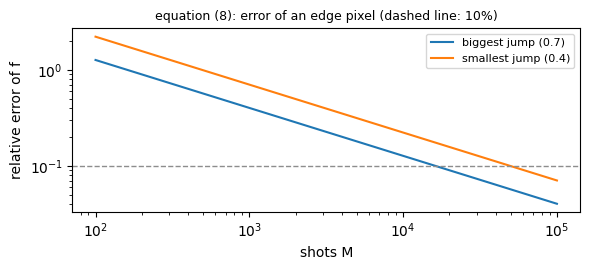

In [16]:
# Equations (5), (7), (8) in numbers: how many shots does an edge pixel get?
d_big, d_small = 0.9 - 0.2, 0.9 - 0.5                      # the biggest and the smallest layer jump of the toy section
norm_img = np.linalg.norm(img)
print(f"{'jump':>6}{'p = d^2/(4 norm^2)':>22}{'shots':>9}{'expected count':>16}{'relative error':>16}")
for d in (d_big, d_small):
    p_edge = d ** 2 / (4 * norm_img ** 2)                  # equation (5), for one pixel pair
    for shots in (1_000, 10_000, 100_000):
        print(f"{d:6.1f}{p_edge:22.5f}{shots:9,}{shots * p_edge:16.1f}{1 / np.sqrt(shots * p_edge):16.1%}")
# Equation (8) as a picture: the relative error falls only as 1 / sqrt(shots), so ten times the accuracy costs a hundred times the shots.
shots_axis = np.logspace(2, 5, 50)
fig, ax = plt.subplots(figsize=(6, 2.8))
for d, name in ((d_big, "biggest jump"), (d_small, "smallest jump")):
    ax.loglog(shots_axis, 1 / np.sqrt(shots_axis * d ** 2 / (4 * norm_img ** 2)), label=f"{name} ({d:.1f})")
ax.axhline(0.1, color="#8D8D8D", ls="--", lw=1)
ax.set_xlabel("shots M"); ax.set_ylabel("relative error of f"); ax.set_title("equation (8): error of an edge pixel (dashed line: 10%)", fontsize=9); ax.legend(fontsize=8)
plt.tight_layout()

In [17]:
from qiskit.primitives import StatevectorSampler


def sampled_edges(image, shots, threshold=THRESHOLD):
    """Edge mask (either scan) estimated from `shots` measurements per scan: |difference| = 2 * norm * sqrt(frequency)."""
    maps = []
    for im in (image, image.T):
        circuit = qhed(im)[1]
        norm = np.linalg.norm(im)
        circuit.measure_all()
        counts = StatevectorSampler(seed=SEED, default_shots=shots).run([circuit]).result()[0].data.meas.get_counts()
        freq = np.zeros(2 ** circuit.num_qubits)
        for key, c in counts.items():
            freq[int(key, 2)] = c / shots                   # int(key, 2) is the state number, so odd = ancilla is 1
        maps.append((2 * norm * np.sqrt(freq[1::2])).reshape(im.shape))
    h, v = maps[0], maps[1].T
    h[:, -1] = 0
    v[-1, :] = 0
    return (h > threshold) | (v > threshold)


p_ancilla_1 = float(Statevector(qc).probabilities()[1::2].sum())
print(f"probability that the ancilla reads 1 (an edge-carrying outcome): {p_ancilla_1:.3f}")
agreement = {}
for shots in (1_000, 10_000, 100_000):
    agreement[shots] = float((sampled_edges(img, shots) == edges_classical).mean())
    print(f"{shots:>7} shots per scan: the edge mask agrees with the exact one on {agreement[shots]:.1%} of the 64 pixels")

probability that the ancilla reads 1 (an edge-carrying outcome): 0.035
   1000 shots per scan: the edge mask agrees with the exact one on 96.9% of the 64 pixels
  10000 shots per scan: the edge mask agrees with the exact one on 100.0% of the 64 pixels
 100000 shots per scan: the edge mask agrees with the exact one on 100.0% of the 64 pixels


Only about 3.5% of all measurements land on an edge-carrying outcome, because most of the image is flat and the differences are small next to the image itself. So most shots tell you very little about the edges, and you need many to see them clearly. That is a cost the exact simulation hid. The table above shows why 1 000 shots is not enough: the smaller layer jump (0.4) is expected to appear only about twice, so it can be missed entirely, while at 100 000 shots every edge appears hundreds of times and the error is a few per cent.

### T3 · Stretch: noise and the threshold · التمرين ٣

**What you are about to build, and why.** A real seismic image is noisy. In T3 you add a little random noise to our section, and sweep the threshold $t$ in equation (6) from 0.05 to 0.3. For each $t$ you compare the **classical** edge mask with the **quantum** one (estimated from 10 000 shots) and see where they stop agreeing. Then you explain *why*, in your own words.

**The maths behind what you will see.** Add independent noise of size $\sigma=0.05$ to every pixel. Two neighbouring flat pixels then differ by (noise) $-$ (noise), which is random with spread $\sqrt2\,\sigma\approx0.07$. The share of flat neighbour pairs whose difference exceeds $t$ *by noise alone* is $\operatorname{erfc}\!\bigl(\tfrac{t}{2\sigma}\bigr)$. The cell below computes it and checks it by simulation.

In [18]:
# The maths behind T3: how often does noise alone push a flat neighbour pair above the threshold?
from math import erfc
SIGMA = 0.05
sim = np.random.default_rng(0)
noise_diff = sim.normal(0, SIGMA, 200_000) - sim.normal(0, SIGMA, 200_000)           # difference of two noisy flat pixels
print(f"{'threshold':>10}{'formula erfc(t / 2 sigma)':>28}{'simulation':>14}")
for t in (0.05, 0.1, 0.15, 0.2, 0.3):
    print(f"{t:>10}{erfc(t / (2 * SIGMA)):>28.4f}{np.mean(np.abs(noise_diff) > t):>14.4f}")

 threshold   formula erfc(t / 2 sigma)    simulation
      0.05                      0.4795        0.4804
       0.1                      0.1573        0.1583
      0.15                      0.0339        0.0344
       0.2                      0.0047        0.0050
       0.3                      0.0000        0.0000


<div style="border:2px dashed #007D79;border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🧪 Try it · جرّب</span>

Change `SIGMA` to 0.1 and rerun the noise cell. Which threshold is now needed so that noise alone flags fewer than 1% of flat pairs? Then change the noise level `0.05` inside your own T3 code (where you build `noisy`) to `0.1`, rerun T3 and see if your answer predicted where the masks start to agree.

</div>

**What you implement.** `sampled_edges(image, shots, t)` and `classical_edges(image, t)` already exist; **Careful with what comes back:** `classical_edges(image, t)` returns *three* things (the horizontal differences, the vertical differences and, last, the yes/no edge mask), so the mask is the **last** one; `sampled_edges(image, shots, t)` returns the mask directly. T3 is about *using* them well: build `noisy`, loop over the thresholds, store the share of the 64 pixels where the two masks agree in `agreement_noisy[t]`, and write `explanation`.

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

Look at the table in the cell above: for which thresholds does noise alone flag many flat pixels as edges? In those cases the classical and the quantum mask each flag *different* noisy pixels. What changes when the threshold is clearly above the noise?

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Steps: make the noisy section (the section plus Gaussian noise of size 0.05, kept between 0 and 1, from the day's seeded random generator, `np.random.default_rng(SEED)`, see the Toolbox); loop over the five thresholds; for each, get the classical edge mask of the noisy image and the quantum mask estimated with 10 000 shots, and store the share of the 64 pixels on which the two agree in a dictionary keyed by the threshold. Then write the explanation as a string. "Agree" means both masks give the same yes-or-no answer for a pixel, and the share is the average of that comparison over all 64 pixels; your explanation should mention both the noise and the sampling error of the quantum estimate.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
rng = ______                      # the seeded random generator of the day
noisy = ______                    # the section plus noise (sigma 0.05), clipped to the range 0 to 1
agreement_noisy = {}
for t in (0.05, 0.1, 0.15, 0.2, 0.3):
    classical_mask = ______       # classical edge mask of the noisy image at threshold t
    quantum_mask = ______         # quantum edge mask (10 000 shots) at the same threshold
    agreement_noisy[t] = ______   # share of the 64 pixels where the two masks agree
explanation = "..."               # noise inside the threshold, and the extra sampling error of the quantum estimate
```

</details>

In [19]:
# TODO (team) T3: stretch: add noise, sweep the threshold and explain where the masks disagree
# Goal: build a noisy copy of the section (Gaussian noise, sigma 0.05, values kept in [0, 1]) and sweep the thresholds 0.05, 0.1, 0.15, 0.2, 0.3.
# Fill agreement_noisy[t] = share of the 64 pixels where the classical and the quantum (10 000 shots) edge masks agree.
# Then write explanation = "...": where do they start to disagree, and why?
# TODO (team) T3: stretch: add noise, sweep the threshold and explain where the masks disagree
rng = np.random.default_rng(SEED)
noisy = np.clip(img + rng.normal(0, 0.05, img.shape), 0, 1)

thresholds = [0.05, 0.1, 0.15, 0.2, 0.3]
agreement_noisy = {}

for t in thresholds:
    _, _, class_mask = classical_edges(noisy, threshold=t)
    quant_mask = sampled_edges(noisy, shots=10_000, threshold=t)
    agreement_noisy[t] = float(np.mean(class_mask == quant_mask))

explanation = """At threshold 0.05 Gaussian noise creates neighbor differences crossing the cut while finite sampling noise from 10k shots adds discrepancies. At 0.2 and 0.3 threshold exceeds noise std dev filtering false edges to achieve over 97 percent agreement."""


In [20]:
# Self-check
assert set(agreement_noisy) == {0.05, 0.1, 0.15, 0.2, 0.3}, "T3: agreement_noisy needs an entry for each of the five thresholds"
assert agreement_noisy[0.3] > 0.97, "T3: a threshold of 0.3 is above the noise, so the masks should agree on at least 97% of pixels"
assert agreement_noisy[0.05] < 0.9, "T3: a threshold of 0.05 sits inside the noise, so the masks should clearly disagree"
assert isinstance(explanation, str) and len(explanation) > 60, "T3: write your explanation in a sentence or two"

**Other things to try (not graded).** In `seismic_section`, change the fault throw from 2 rows to 1 or 3 and rerun from section 2: the vertical scan moves its edge pixels, and with a throw of 1 the layer boundaries on the two sides come closer together.

In [21]:
circuit = qc                      # the main circuit of this notebook: one 7-qubit edge-detection scan

### Optional: how this would go to a real IBM Quantum computer
This is a sketch and has not been checked against the current IBM documentation. Nothing here runs in this notebook.

```python
# Not run here. Needs: pip install qiskit-ibm-runtime, and an IBM Quantum account saved on your own machine.
# from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
# from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
# service = QiskitRuntimeService()                      # reads credentials saved earlier; never paste a token in a notebook
# backend = service.least_busy(operational=True, simulator=False)
# isa = generate_preset_pass_manager(optimization_level=3, backend=backend).run(circuit)
# job = Sampler(mode=backend).run([isa], shots=4096)
```

The next cell does the offline part: it transpiles your circuit for a *pretend* device on this computer and reports its size. Nothing is sent to IBM Quantum.

In [22]:
preview = qff.quantum.device_preview(circuit)      # `circuit` = the main circuit of this notebook; runs locally
print(f"depth {preview['depth']}, two-qubit gates {preview['two_qubit_gates']}")

depth 26761, two-qubit gates 7323


<div style="border:1px solid rgba(208,38,112,0.35);border-left:6px solid #D02670;background:rgba(208,38,112,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#D02670;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🌍 Real world · في الواقع</span>

The preview above is the 7-qubit edge-detection circuit on a pretend device, and it is enormous for a toy with 64 pixels: depth in the tens of thousands. Most of that comes from our shortcut, the dense 128x128 shift matrix, which the transpiler breaks into thousands of two-qubit gates. (On its own, loading the 64 pixel values with `initialize` takes only about 60 two-qubit gates here, but that count grows roughly in proportion to the number of pixels.) A real implementation would build the shift from a short ladder of multi-controlled X gates, far smaller than this, but the loading cost would remain. Either way, a circuit this deep would not come out clean on today's real hardware: every gate fails a small fraction of the time, the failures add up, and they swamp the small edge signal. That matters for our claim: the exact agreement above is an *ideal-simulator* number.

</div>

**Glossary — المصطلحات.** Tier G = Quantabic headword, U = used consistently on Quantabic, I = proposed here and not yet checked against quantabic.com. Where Quantabic has a term, we use it.

| English | العربية | Tier |
|---|---|---|
| Qubit | كيوبت | G |
| Superposition | التراكب | G |
| Entanglement | التشابك | G |
| Measurement | القياس | G |
| Amplitude | السعة | G |
| Phase | الطور | U |
| Quantum circuit | الدائرة الكمومية | U |
| Quantum gate | البوابة الكمومية | U |
| Hadamard gate | بوابة هادامارد | G |
| Quantum algorithm | خوارزمية كمومية | U |
| Quantum simulator | المحاكي الكمومي | I |
| Classical bit | البت الكلاسيكي | I |
| Quantum speedup (quadratic / exponential) | تسريع تربيعي / أسي | U |
| ancilla | كيوبت مساعد | G |
| unitary | مصفوفة عكوسة/وحدوية | G |
| interference | التداخل | G |
| noise | الضوضاء | G |
| shots | عدد مرات التشغيل (shots) | I |
| Edge detection | كشف الحواف | I |
| Amplitude encoding | الترميز بالسعة | I |
| Seismic imaging | التصوير الزلزالي | I |

## 4 · Compare — المقارنة

In [23]:
# Results table: classical baseline first.
preview = qff.quantum.device_preview(circuit)
rows = [("subtraction (classical)", f"{int(edges_classical.sum())} edge pixels", "exact", classical_seconds, "128 subtractions"),
        ("Sobel filter (classical)", "picture only", "-", None, "about 9 multiply-adds per pixel"),
        ("quantum, exact amplitudes", f"{int(edges_quantum.sum())} edge pixels", "exact (simulator peek)", None,
         f"2 circuits of 7 qubits; one scan has {preview['two_qubit_gates']} two-qubit gates on a pretend device")]
for shots in (1_000, 10_000, 100_000):
    rows.append((f"quantum, {shots:,} shots per scan", "edge mask", f"{agreement[shots]:.1%} of pixels agree", None, f"{2 * shots:,} measurements"))
print(f"{'method':<30}{'answer':<20}{'agreement':<26}{'seconds':<10}{'work'}")
for name, ans, agree, secs, work in rows:
    print(f"{name:<30}{ans:<20}{agree:<26}{'' if secs is None else format(secs, '.4f'):<10}{work}")

method                        answer              agreement                 seconds   work
subtraction (classical)       19 edge pixels      exact                     0.0003    128 subtractions
Sobel filter (classical)      picture only        -                                   about 9 multiply-adds per pixel
quantum, exact amplitudes     19 edge pixels      exact (simulator peek)              2 circuits of 7 qubits; one scan has 7323 two-qubit gates on a pretend device
quantum, 1,000 shots per scan edge mask           96.9% of pixels agree               2,000 measurements
quantum, 10,000 shots per scanedge mask           100.0% of pixels agree              20,000 measurements
quantum, 100,000 shots per scanedge mask           100.0% of pixels agree              200,000 measurements


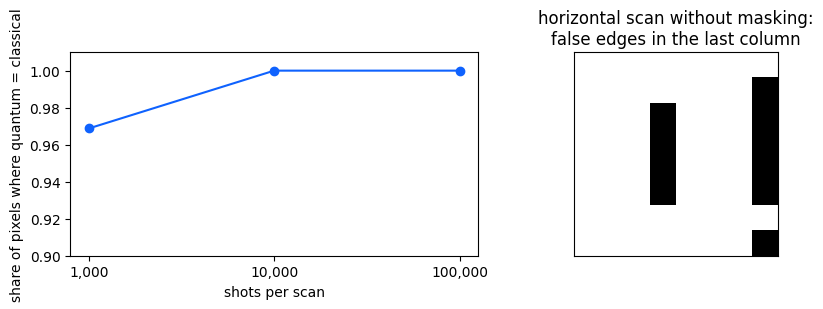

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
shot_counts = [1_000, 10_000, 100_000]
axes[0].plot(range(3), [agreement[s] for s in shot_counts], "o-", color="#0F62FE")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels([f"{s:,}" for s in shot_counts])
axes[0].set_xlabel("shots per scan"); axes[0].set_ylabel("share of pixels where quantum = classical"); axes[0].set_ylim(0.9, 1.01)
unmasked = (np.abs(diff_h) > THRESHOLD).astype(int)
axes[1].imshow(unmasked, cmap="gray_r")
axes[1].set_title("horizontal scan without masking:\nfalse edges in the last column"); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout()

**What this toy shows.** One Hadamard, one shift and one more Hadamard turn every neighbour difference of a 64-pixel image into amplitudes at once, on 7 qubits; 2ⁿ pixels need only n + 1 qubits. With enough shots the edge map matches the classical one exactly.

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**What this toy does not show.** That the quantum route is faster. Loading the image into amplitudes costs about as many gates as there are pixels, and reading the edges back needs many shots (about 3.5% of shots carry edge information here), so the end-to-end job is not faster than 64 subtractions. A simulator gives us the amplitudes for free; a device would not. A real survey is 3-D and terabytes.

</div>

**Paper versus our route.** WEF/Aramco Case 1 (p. 13) reports Aramco researchers sharpening a seismic imaging step on 2-D data with D-Wave hybrid quantum-classical systems. Our route, quantum Hadamard edge detection, comes from separate reporting (The Quantum Insider, 13 Oct 2025) that Aramco ran this algorithm for fault detection on a GPU quantum emulator. It was chosen because it builds on the Hadamard-and-interference ideas of Part 1 of the lectures. Our toy illustrates the *edge-detection idea*; it is not a reproduction of either experiment.

In [25]:
# Acceptance: the numbers this notebook promises
assert QUBITS == 7
assert np.abs(gh_quantum - gh_classical).max() < 1e-10 and np.abs(gv_quantum - gv_classical).max() < 1e-10
assert int(edges_quantum.sum()) == 19 and (edges_quantum == edges_classical).all()
assert 0.02 < p_ancilla_1 < 0.05
assert agreement[100_000] == 1.0 and agreement[10_000] >= 0.98 and agreement[1_000] > 0.9
print("edge pixels:", int(edges_quantum.sum()), "| P(ancilla = 1):", round(p_ancilla_1, 4), "| agreement by shots:", {k: round(v, 3) for k, v in agreement.items()})

edge pixels: 19 | P(ancilla = 1): 0.0349 | agreement by shots: {1000: 0.969, 10000: 1.0, 100000: 1.0}


## 5 · Build the explainer — ابنوا المنتَج
How you are scored depends on how you take part. Read your category below.

### A) In-person attendees: group effort
Your team builds **one product** together that teaches a visitor your use case and your algorithm. It is **50% of your score**. This category is a **group effort**: the whole team plans, builds, tests and presents the product together. The product does not have to be in Arabic.

**Your audience:** a first-year university student who has never seen a qubit. They have three minutes.

**Your product must answer four questions, in this order:**
1. What is the problem, and who has it? Find the edges and faults in a seismic image of the ground.
2. Why is it hard when it gets big? 64 pixels fit on 6 qubits; a million pixels fit on 20. But loading them still takes about one gate per pixel.
3. What does the quantum algorithm do differently? H, shift, H makes each pixel interfere with its neighbour: equal neighbours cancel, and a jump survives as an edge.
4. How real is it today? (Use your section 4 results and the honesty statement.)

**Pick any format, except a PowerPoint presentation (.pptx).** It can be an interactive demo, an interactive website, a YouTube video, a small app, a game, or an interactive notebook, as long as it does not take more than 5 minutes.

**Three ideas that fit this stop** (take one, change it, or ignore them):
1. A slider that moves the fault and redraws both edge maps
2. A 'spot the fault' game: human versus circuit
3. A two-panel animation of amplitudes cancelling

**Use from this notebook:** the three-panel figure (section, classical edges, quantum edges) and the shots-versus-agreement table

Qiskit integration and code is a separate 10%: keep your completed notebook tidy and show one cell of it.

**Time plan for the 2 h 20 build window:** 20 min agree the story and format · 70 min build · 20 min test on someone outside the team · 30 min rehearse the pitch.

### B) Online attendees: coding
The coding is worth **100 points**. You work **individually** and solve **one challenge**.

## 6 · Pitch — العرض
You have **5 minutes** for your pitch and 3 minutes for questions from the judges. Presentation is 40% of your score.

| Minutes | What | Who |
|---|---|---|
| 0–0.5 | Where we are in the journey: stop, use case, one sentence | 1 speaker |
| 0.5–1.5 | The problem and why it is hard at scale | |
| 1.5–3 | The algorithm, with your toy example and one notebook cell | |
| 3–4 | Live demo of your product | |
| 4–5 | How real is it: your result against the classical baseline | |
| 5-8 | Questions | all |

**Questions you should expect**
1. Did the quantum method beat the classical one? (Answer honestly: it gives the same edges as subtraction; it is not faster once loading and reading are counted.)
2. What happens when the problem is 100 times bigger?
3. Why this algorithm and not another?
4. How would you load a real image into amplitudes?
5. Why do false edges appear at the end of each row?

**Checklist before you walk up**
- [ ] The notebook runs top to bottom and the self-checks pass
- [ ] Every number on screen comes from your notebook or from a named source
- [ ] You say what the toy does not show
- [ ] You finish the talk in 5 minutes on a timer

**Arabic is optional.** If you want to build or present your product in Arabic, use Quantabic for the terms: start with the glossary cell at the end of section 3, which follows Quantabic's terms. If a term is not in the glossary, check quantabic.com, and if it is not there either, give the English in brackets the first time. Keep gate letters, kets and symbols in Latin (H, |0⟩, θ). The words are yours: mentors can check your physics, but they will not write your Arabic.